<a href="https://colab.research.google.com/github/ruelenslais9-spec/MV2627_Exercises/blob/main/Project2627/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<font color ='Navy'><center> __BruFace__ </center></font>
<br> MA1 Mechanical Engineering <br>  __Mechanical vibrations__ <br>
**Academic Year 2026-2027**
***
<font color='Navy'><h1><center>Project: 4 DOFs Model of a Car Under Road Excitation </center></h1></font>
- Arnaud Deraemaeker ([Arnaud.Deraemaeker@ulb.be](mailto:Arnaud.Deraemaeker@ulb.be))  
- Wout Weijtjens ([Wout.Weijtjens@vub.be](mailto:Wout.Weijtjens@vub.be))
***


# **1. Model and equations**

Consider the 4 DOFs model of a car represented below. $X_{01}$ and $X_{02}$ represent the motion imposed on each wheel due to the road profile. The car body is assumed to be rigid and the motion is restricted to a plane, resulting in 2 DOFs (translation, rotation), while each wheel is also assumed to be a rigid body and can only move vertically. $K_0, B_0$ are the mechanical parameters of the car suspension, while $k, b$ are the stiffness and damping of the tires.

---

## **Model Diagram**
![4 DOFs Model of a Car](https://github.com/OWI-Lab/MV2627_Exercises/blob/main/Project2627/images/car.png?raw=1)

---

1. Based on the equations of motion derived for each body separately, derive the full set of equations of motion for the car in a matrix form, and determine the mass, damping, and stiffness matrices. Use absolute displacements in the equations. Give the expression of the force vector.

2. Assume harmonic excitation and write the equations of motion in the frequency domain.
What assumption could you make to have the force vector independent of the frequency?
Give the expression of the force vector in this simplified case.

***Small Angle Assumption*** : It is assumed that the rotation angles of the car body are small enough such that $sin⁡(q3)≈q3$. This linearizes the rotational dynamics, allowing for the use of linear equations of motion.


In [21]:
import sys
import os

# Only if the session is opend in google colab link
if "google.colab" in sys.modules:
    repo = "/content/MV2627_Exercises"
    if not os.path.exists(repo):
        !git clone -q https://github.com/OWI-Lab/MV2627_Exercises.git {repo}
    %cd /content/MV2627_Exercises/Project2627
    !pip install -q uv

/content/MV2627_Exercises/Project2627


# **2. Frequency Domain Computations**

Consider the following values of the parameters:
- $M_0 = 1500 \, \text{kg}$
- $K_0 = 65 000 \, \text{N/m}$
- $B_0 = 65 \, \text{N/(m/s)}$
- $m = 10 \, \text{kg}$
- $k = 100 000 \, \text{N/m}$
- $b = 10 \, \text{N/(m/s)}$
- $L = 4 \, \text{m}$
- $I_G = 5700 \, \text{kg} \cdot \text{m}^2$

Answer the following questions providing your answer to each question in the cell below it and in a separate code cell.

## **2.1 Computation of transmissibilities**


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Compute the mode shapes and the natural frequencies of the car. Give a physical interpretation of each of the mode shapes (what kind of motion of the car is related to each mode shape)

</div>

In [22]:
import numpy as np
from scipy import linalg as la

def calc_eigenvalues_eigenvectors(M:np.array,K:np.array):

    (lamb,psi)=la.eig(K,M)
    idx = lamb.argsort()  # sort the eigenvalues and eigenvectors with lowest eigenvalue first
    lamb = lamb[idx]
    psi = psi[:,idx]

    return lamb, psi

#variable definition :
m=10
M0=1500
IG=5700
k=100000
K0=65000
L=4
b=10
B0=65
#Matrix computation :
M=np.array([[m,0,0,0],
            [0,m,0,0],
            [0,0,M0,0],
            [0,0,0,IG]])

K=np.array([[k+K0,0,-K0,L/2*K0],
            [0,k+K0,-K0,-L/2*K0],
            [-K0,-K0,2*K0,0],
            [L/2*K0,-L/2*K0,0,L**2/2*K0]])

C=np.array([[b+B0,0,-B0,L/2*B0],
            [0,b+B0,-B0,-L/2*B0],
            [-B0,-B0,2*B0,0],
            [L/2*B0,-L/2*B0,0,L**2/2*B0]])

#natural frequencies and mode shape computation :

lamb,Psi = calc_eigenvalues_eigenvectors(M,K)
nat_freq=np.sqrt(lamb)/(2*np.pi)

for i in range(4) :
  print("mode shape ",i+1," : ")
  print("mode shape freq = ", np.real(nat_freq[i]))
  print("mode shape = ", Psi[:,i])    #the mode shape is the column of the Psi matrix
  print("==============")

# for 1.15Hz (Mode shape 1) -> same amount of displacement for X1 and X2 in the same direction, we get a X3 displacement in the same direction as the wheel displacement (car bouncing)
# for 1.18Hz (Mode shape 2) -> same amount of displacement for X1 and X2 but in opposite direction, we get no X3 displacement but a rotation of the car q3 (car pitching)
# for 20.465Hz (Mode shape 3) -> same amount of displacement for X1 and X2 in the same direction, we get a X3 displacement in the opposite direction as the wheel displacement (car bouncing) but way less than at 1.15Hz (the chassis almost stay at rest)
# for 20.466Hz (Mode shape 4) -> same amount of displacement for X1 and X2 in the opposite direction, we get no x3 displacement but a q3 rotation way lower than at low frequency (chassis also almost at rest)

mode shape  1  : 
mode shape freq =  1.1522691257722917
mode shape =  [-3.44973003e-01 -3.44973003e-01 -8.72918813e-01  3.83357161e-15]
mode shape  2  : 
mode shape freq =  1.1821385236486825
mode shape =  [-5.27032217e-01  5.27032217e-01 -1.18811614e-14  6.66688896e-01]
mode shape  3  : 
mode shape freq =  20.46502994619568
mode shape =  [-7.07101873e-01 -7.07101873e-01  3.72590673e-03  1.45577055e-15]
mode shape  4  : 
mode shape freq =  20.46614924817183
mode shape =  [ 7.07105421e-01 -7.07105421e-01 -2.14910555e-15  1.96134164e-03]


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. Assuming $X_{01} = X_{02}$ , compute and represent the transmissibility $X_{3}/X_{01}$ using the full model with the coupled equations (no simplification of the force vector). Identify to which mode shapes and resonance frequencies the peaks in the transmissibility curve belong. Which kind of imposed motion is applied when X01 = X02? Can you make a link with the peaks present in the transmissibility curve?

</div>

**1) Compute and represent the transmissibility  $X_3/X_{01}$  using the full model with the coupled equations (no simplification of the force vector) :**

By hand comutation, we can solve our system of equation knowing $X_{01}=X_{02}$. First step would be to express the whole set of equation in the Laplace domain (by considering the initial conditions as 0).
We can then subtract eq2 to eq1 (1)-(2) which will give us :

\begin{equation}
(X_1(s)-X_2(s))(ms^2+(b+B_0)s+(k+K_0))=0 ==>
X_1(s)=X_2(s)
\end{equation}

Now that we know that $X_1(s)=X_2(s)=X(s)$ (to simplify our life), we can inject this in eq3 which will provide us this equation :
\begin{equation}
X_3(s)(M_0s^2+2B_0+2K_0)-X(s)(2B_0+2K_0)=0
\end{equation}
We can derive the transfer function of $X_3/X = X_3/X_1$ (which links the chassis response to the wheel excitation) :

\begin{equation}
\frac{X_3(s)}{X_1(s)}=\frac{2B_0+2K_0}{M0s^2+2B_0s+2K_0}
\end{equation}

Ok but we want the chassis response in respect to the road excitation => $X_3/X_{01}$ = $X_3/X_1 * X_1/X_{01}$ => We need $X_1/X_{01}$.
We can get it only by looking at eq1 (the wheel 1 equation). We can express $X_3$ as an $X_1$ function thanks to our previous result but what about $q_3$ ? The eq4 provides us in Laplace domain :
\\
\begin{equation}
Q3(s)(J_0s^2+\frac{L^2}{2}B0s+\frac{L^2}{2}K0)+(X_1(s)-X_2(s))(\frac{L}{2}B_0s+\frac{L}{2}K_0)=0
\end{equation}

But $X_1-X_2=0$ so :

\begin{equation}
Q_3(s)(J_0s^2+\frac{L^2}{2}B0s+\frac{L^2}{2}K0)=0 ==> Q_3(s)=0
\end{equation}

We are set to compute $X_1/X_{01}$ with eq1 by injecting $X_3(s)$ and knowing $Q_3(s)=0$ :

\begin{equation}
\frac{X_1}{X_{01}}=\frac{bs+k}{ms^2+(B_0+b-\frac{B_0(2B_0s+2K_0)}{M_0s^2+2B_0s+2K_0})s+(K_0+k-\frac{K_0(2B_0s+2K_0)}{M_0s^2+2B_0s+2K_0})}
\end{equation}

Which simplify to :  
\begin{equation}
\frac{X_1}{X_{01}}=\frac{(bs+k)(M_0s^2+2B_0s+2K_0)}{(ms^2+bs+k)(M_0s^2+2B_0s+2K_0)+(B_0s+K_0)M_0s^2}
\end{equation}
And then, finally :

\begin{equation}
\frac{X_3}{X_{01}}=\frac{2(bs+k)(B_0s+K_0)}{[ms^2+(B_0+b-\frac{B_0(2B_0s+2K_0)}{M_0s^2+2B_0s+2K_0})s+K_0+k-\frac{K_0(2B_0s+2K_0)}{M_0s^2+2B_0s+2K_0}](M_0s^2+2B_0s+2K_0)}
\end{equation}

We can simplify it as :

\begin{equation}
\frac{X_3}{X_{01}}=\frac{2(B_0s+K_0)(bs+k)}{(ms^2+bs+k)(M_0s^2+2B_0s+2K_0)+(B_0s+K_0)M_0s^2}
\end{equation}

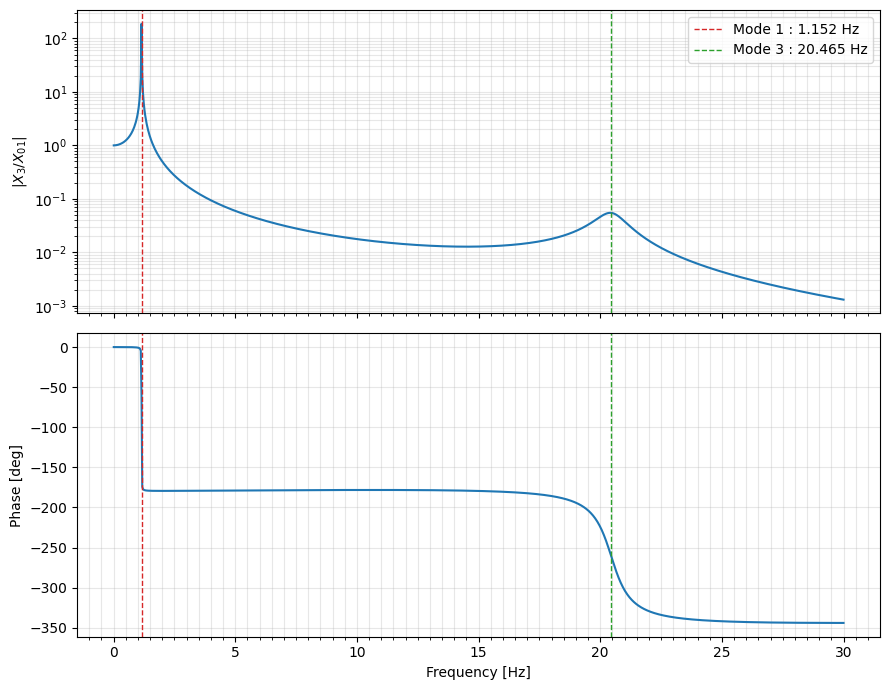

In [43]:
#Now, we are going to plot the transfer function X3/X01 (we only have to evaluate it in s=jw for our Bode plot)

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

def transfer_function_computation_X3(freq,m,b,k,M0,B0,K0) :
  w=2*np.pi*freq
  transfer_function=2*(B0*1j*w+K0)*(b*1j*w+k)/((-m*w*w+1j*w*b+k)*(-M0*w*w+1j*2*w*B0+2*K0)-(B0*1j*w+K0)*M0*w*w)
  return transfer_function

#initialisation
freq=np.linspace(0.01,30,1000)
transfer_function_X3 = np.zeros(np.size(freq),dtype=complex)
transfer_function_magnitude = np.zeros(np.size(freq))
transfer_function_phase = np.zeros(np.size(freq))

#we compute the value of the transfer function (for each freq) => gives us a complex number that we store in transfer_function
for i in range (np.size(freq)) :
  transfer_function_X3[i]=transfer_function_computation_X3(freq[i],m,b,k,M0,B0,K0)

#then we compute the modulus and the phase of transfer_function and we store them (here we have real values)
transfer_function_magnitude=np.abs(transfer_function_X3)
transfer_function_phase=np.unwrap(np.angle(transfer_function_X3)) * 180/np.pi #unwrap cause we could exceed the -pi;pi intervall (which will result in jumps in the plot...) + 180/pi to convert into degrees :)

#============== plot section =================== (Use of AI here to generate structurate plot)

f_modes = [1.1522691257722917, 20.46502994619568] #the translation frequencies (only interesting one here Q_3 being 0 as seen)
labels  = [f"Mode 1 : {f_modes[0]:.3f} Hz", f"Mode 3 : {f_modes[1]:.3f} Hz"]
colors  = ['tab:red', 'tab:green']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
#Magnitude plot
ax1.semilogy(freq, transfer_function_magnitude , color='tab:blue')
ax1.set_ylabel(r'$|X_3/X_{01}|$')
ax1.grid(True, which='both', alpha=0.3)

#phase plot
ax2.plot(freq, transfer_function_phase, color='tab:blue')
ax2.set_ylabel('Phase [deg]')
ax2.set_xlabel('Frequency [Hz]')
ax2.grid(True, which='both', alpha=0.3)

# plot of the eigen frequecies
for f0, lab, c in zip(f_modes, labels, colors):
    ax1.axvline(f0, color=c, ls='--', lw=1, label=lab)
    ax2.axvline(f0, color=c, ls='--', lw=1)
    ax1.xaxis.set_minor_locator(MultipleLocator(0.5))

ax1.legend()
plt.tight_layout()
plt.show()


**2) Identify to which mode shapes and resonance frequencies the peaks in the transmissibility curve belong :**
On distingue 2 pics sur notre courbe. Le premier aux alentours des 1,15Hz et le second aux alentours des 20,5Hz. Ces 2 pics correspondraient respectivement aux modes shapes 1 et 3 de notre système. (Note : le mode shape 3 et le mode shape 4 sont très proches l'un de l'autre mais intuitivement on ne s'attend pas vraiment à avoir de rotation dans le système avec $X_{01}=X_{02}$, il est alors raisonnable de dire que le mode shape mis en évidence ici est le 3).

**3) Which kind of imposed motion is applied when $X_{01} = X_{02}$ :**
Ce serait une translation pure et simple de la route

**4) Can you make a link with the peaks present in the transmissibility curve :** On pourrait distinguer 2 types de mode shapes dans notre système. Les modes 1 et 3 seraient symétriques (réponse identiques pour les 2 roues $X_1=X_2$) tandis que les modes 2 et 4 seraient anti-symétriques (réponse opposée des 2 roues $X_1=-X_2$). Si on projettait l'excitation fournie par $X_{01}$ et $X_{02}$ dans la base modale ($\Psi^T{F}$), le résultat dépendrait du type d'excitation. Pour notre cas, $X_{01}=X_{02}$ = excitation symétrique. Cela signifie que seuls les modes symétriques vont être excités : $\Psi_1^T{F}$ et $\Psi_3^T{F} \neq 0$ tandis que les modes antisymétriques ne seront absolument pas excités : $\Psi_2^T{F}$ et $\Psi_4^T{F} = 0$ ! On observe donc uniquement les modes symétriques dans notre réponse.

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

3. Now, use the simplified force vector derived in point 1.2, compute and represent the transmissibility $X_{3}/X_{01}$ using the full model with the coupled equations. Compare with the previous case by plotting the two curves on the same graph and comment. Is the simplification used for the force vector valid in your opinion?

</div>


In this case :

\begin{equation}
\frac{X_3}{X_{01}}=\frac{2(B_0s+K_0)(bs+k)}{(ms^2+bs+k)(M_0s^2+2B_0s+2K_0)+(B_0s+K_0)M_0s^2}
\end{equation}
Becomes :

\begin{equation}
\frac{X_3}{X_{01}}=\frac{2(B_0s+K_0)k}{(ms^2+bs+k)(M_0s^2+2B_0s+2K_0)+(B_0s+K_0)M_0s^2}
\end{equation}
(We just set b=0 in the bs+k term which is the excitation contribution).

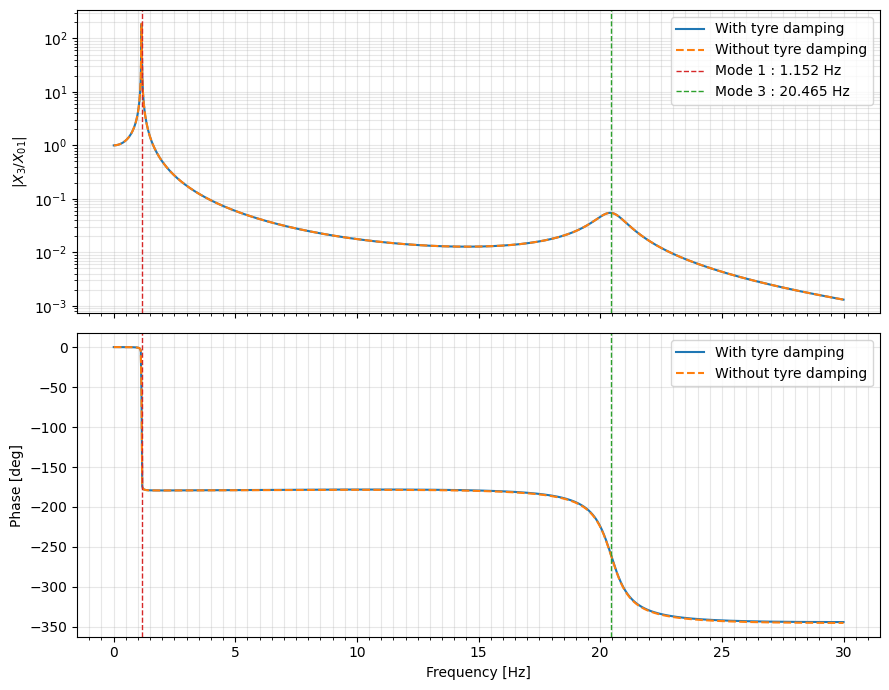

0.054592923687922706
0.054588410995424524
magnitude relative error (mode 3) :  0.008266075881882653 %


In [24]:
#we re-use the previous code but we will add the simplify transfer function to compare it with the previous one.

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator


def transfer_function_computation_X3(freq,m,b,k,M0,B0,K0) :
  w=2*np.pi*freq
  transfer_function=2*(B0*1j*w+K0)*(b*1j*w+k)/((-m*w*w+1j*w*b+k)*(-M0*w*w+1j*2*w*B0+2*K0)-(B0*1j*w+K0)*M0*w*w)
  return transfer_function

#to compute with ONLY the force vector simplification !!! (we do not say b=0 in the system dynamic but only in the force vector !)
def transfer_function_simplify_computation_X3(freq,m,b,k,M0,B0,K0) :
  w=2*np.pi*freq
  transfer_function_simplify=2*(B0*1j*w+K0)*k/((-m*w*w+1j*w*b+k)*(-M0*w*w+1j*2*w*B0+2*K0)-(B0*1j*w+K0)*M0*w*w)
  return transfer_function_simplify

#full model initialisation
freq=np.linspace(0.01,30,1000)
transfer_function_X3 = np.zeros(np.size(freq),dtype=complex)
transfer_function_X3_magnitude = np.zeros(np.size(freq))
transfer_function_X3_phase = np.zeros(np.size(freq))


#simplify model initialisation
transfer_function_simplify_X3 = np.zeros(np.size(freq),dtype=complex)
transfer_function_simplify_X3_magnitude = np.zeros(np.size(freq))
transfer_function_simplify_X3_phase = np.zeros(np.size(freq))

#then we evaluate for each freq and for both model the transfer function value (complex)
for i in range (np.size(freq)) :
  transfer_function_X3[i]=transfer_function_computation_X3(freq[i],m,b,k,M0,B0,K0)
  transfer_function_simplify_X3[i]=transfer_function_simplify_computation_X3(freq[i],m,b,k,M0,B0,K0)

#then we take the full vector of complex number evaluated in the loop and we compute the modulus and the phase for the full and simplify model
transfer_function_X3_magnitude=np.abs(transfer_function_X3)
transfer_function_X3_phase=np.unwrap(np.angle(transfer_function_X3)) * 180/np.pi #unwrap cause we could exceed the -pi;pi intervall (which will result in jumps in the plot...) + 180/pi to convert into degrees :)

transfer_function_simplify_X3_magnitude=np.abs(transfer_function_simplify_X3)
transfer_function_simplify_X3_phase=np.unwrap(np.angle(transfer_function_simplify_X3)) * 180/np.pi



#============== plot section =================== (Use of AI here to generate structurate plot)

f_modes = [1.1522691257722917, 20.46502994619568]
labels  = [f"Mode 1 : {f_modes[0]:.3f} Hz", f"Mode 3 : {f_modes[1]:.3f} Hz"]
colors  = ['tab:red', 'tab:green']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

# Magnitude plot
ax1.semilogy(freq, transfer_function_magnitude,
             color='tab:blue', label='With tyre damping')

ax1.semilogy(freq, transfer_function_simplify_X3_magnitude,
             color='tab:orange', linestyle='--', label='Without tyre damping')

ax1.set_ylabel(r'$|X_3/X_{01}|$')
ax1.grid(True, which='both', alpha=0.3)

# Phase plot
ax2.plot(freq, transfer_function_phase,
         color='tab:blue', label='With tyre damping')

ax2.plot(freq, transfer_function_simplify_X3_phase,
         color='tab:orange', linestyle='--', label='Without tyre damping')

ax2.set_ylabel('Phase [deg]')
ax2.set_xlabel('Frequency [Hz]')
ax2.grid(True, which='both', alpha=0.3)

# Plot of the eigen frequencies
for f0, lab, c in zip(f_modes, labels, colors):
    ax1.axvline(f0, color=c, ls='--', lw=1, label=lab)
    ax2.axvline(f0, color=c, ls='--', lw=1)
    ax1.xaxis.set_minor_locator(MultipleLocator(0.5))

ax1.legend()
ax2.legend()

plt.tight_layout()
plt.show()

#We are just evaluating the TF at the third mode (where the discrepency is visible between the two models) to compute the relative error
f0 = 20.465
print(abs(transfer_function_computation_X3(f0, m, b, k, M0, B0, K0)))   # Full model
print(abs(transfer_function_simplify_computation_X3(f0, m, b, k, M0, B0, K0)))   # No tyre damping (b=0 in the force) model
rel_error=(abs(transfer_function_simplify_computation_X3(f0, m, b, k, M0, B0, K0))-abs(transfer_function_computation_X3(f0, m, b, k, M0, B0, K0)))/abs(transfer_function_computation_X3(f0, m, b, k, M0, B0, K0))*100 #in percent
print('magnitude relative error (mode 3) : ',abs(rel_error),'%')

The simplification applied to the force vector is entirely reasonable.By comparing the two transmissibility values (simplified and full) at 20.465 Hz, we obtain a relative error of the order of $\epsilon_{rel}\approx0.0083\%$ !

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

4. Assuming $X_{01} = −X_{02}$ , compute and represent the transmissibility $q_{3}/X_{01}$ using the full model with the coupled equations (no simplification of the force vector). Identify to which mode shapes and resonance frequencies the peaks in the transmissibility curve belong. Which kind of imposed motion is applied when $X_{01} = −X_{02}$ ? Can you make a link with the peaks present in the transmissibility curve?

</div>


**1) Compute and represent the transmissibility $q_3/X_{01}$  using the full model with the coupled equations (no simplification of the force vector) :**

By hand computation, we can solve our system of equation knowing  $X_{01}=-X_{02}=X_0$ . First step would be to express the whole set of equation in the Laplace domain (by considering the initial conditions as 0). We can then subtract eq2 to eq1 (1)-(2) which will give us :
\begin{equation}
  (ms^2+(b+B_0)s+(k+K_0))(X_1(s)-X_2(s))+L(B_0s+K_0)Q_3(s)=2(bs+k)X_0(s)
\end{equation}

We would then have :

\begin{equation}
  X_1(s)-X_2(s)=\frac{2(bs+k)X_0(s)-L(B_0s+K_0)Q_3(s)}{(ms^2+(b+B_0)s+(k+K_0))}
\end{equation}

We can inject this in the fourth equation, that will provide us after some calculation :

\begin{equation}
  \frac{Q_3}{X_0}=\frac{Q_3}{X_{01}}=\frac{-L(B_0s+K_0)(bs+k)}{(ms^2+(b+B_0)s+(k+K_0))(J_0s^2+\frac{L^2}{2}(B_0-\frac{B_0(B_0s+K_0)}{ms^2+(b+B_0)s+(k+K_0)})s+\frac{L^2}{2}(K_0-\frac{K_0(B_0s+K_0)}{ms^2+(b+B_0)s+(k+K_0)}))}
\end{equation}

Which could be simplify in :

\begin{equation}
\frac{Q_3}{X_{01}}=\frac{-L(B_0s+K_0)(bs+k)}{J_0s^2\left(ms^2+(b+B_0)s+k+K_0\right)+\frac{L^2}{2}(B_0s+K_0)(ms^2+bs+k)}
\end{equation}


Beyond the transfer function, it can be shown that $X_3=0$ in this case. Let us add (1) and (2), which gives:

\begin{equation}
  \left(ms^2+(b+B_0)s+k+K_0\right)(X_1+X_2)-2(B_0s+K_0)X_3=0 .
\end{equation}

We can then substitute $(X_1+X_2)$ into equation (3), which would give:
\begin{equation}
  X_3\left[M_0s^2+\frac{2(B_0s+K_0)(ms^2+bs+k)}{ms^2+(b+B_0)s+k+K_0}\right]=0 .
\end{equation}

If the system is damped ($b$ and $B_0 \neq 0$), the terms in brackets are always non-zero => $X_3$=0. If the system is undamped, we could find zeros in the numerator (at the natural frequencies; we simply set $s=j\omega$ and solve for $\omega$ by bringing everything to the same denominator, etc.) and $X_3\neq0$ would then be a possible solution at those frequencies.

Note: It turns out that the frequencies at which the brackets cancel out are the frequencies of the symmetric modes (modes 1 and 3), namely 1.152 Hz and 20.465 Hz.

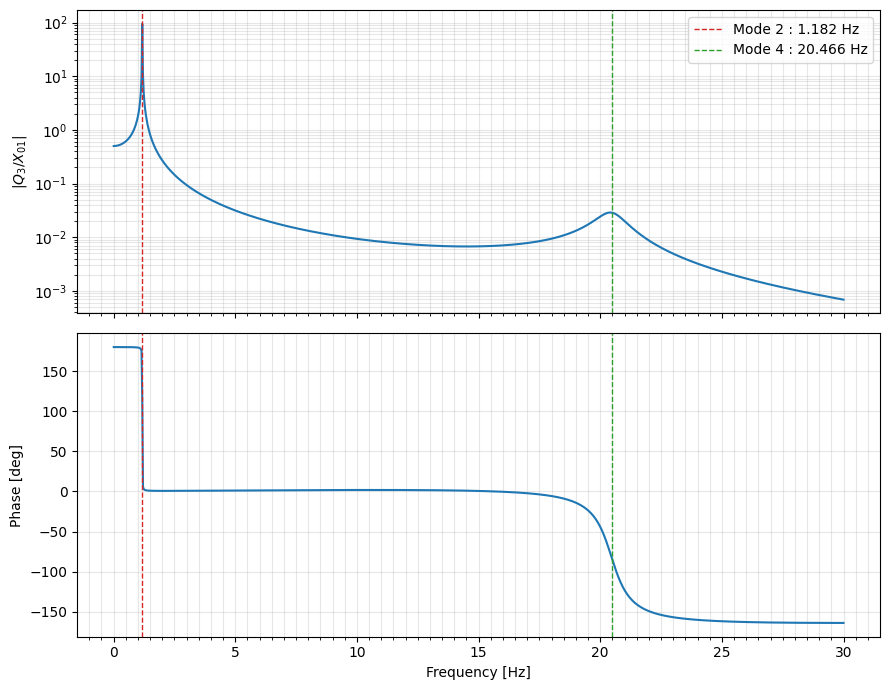

In [41]:
#Now, we are going to plot the transfer function Q3/X01 (we only have to evaluate it in s=jw for our Bode plot)

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

def transfer_function_computation_Q3(freq,m,b,k,M0,B0,K0) :
  w=2*np.pi*freq
  transfer_function=-L*(B0*1j*w+K0)*(b*1j*w+k)/((-IG*w*w)*(-m*w*w+1j*w*(b+B0)+k+K0)+(L**2/2)*(B0*1j*w+K0)*(-m*w*w+1j*w*b+k))
  return transfer_function

#initialisation
freq=np.linspace(0.01,30,1000)
transfer_function_Q3 = np.zeros(np.size(freq),dtype=complex)
transfer_function_magnitude = np.zeros(np.size(freq))
transfer_function_phase = np.zeros(np.size(freq))

#we compute the value of the transfer function (for each freq) => gives us a complex number that we store in transfer_function
for i in range (np.size(freq)) :
  transfer_function_Q3[i]=transfer_function_computation_Q3(freq[i],m,b,k,M0,B0,K0)

#then we compute the modulus and the phase of transfer_function and we store them (here we have real values)
transfer_function_magnitude=np.abs(transfer_function_Q3)
transfer_function_phase=np.unwrap(np.angle(transfer_function_Q3)) * 180/np.pi #unwrap cause we could exceed the -pi;pi intervall (which will result in jumps in the plot...) + 180/pi to convert into degrees :)

#============== plot section =================== (Use of AI here to generate structurate plot)

f_modes = [1.1821385236486825,20.46614924817183] #the rotation frequencies (only interesting one here for the comparaison X_3 being 0 as seen)
labels  = [f"Mode 2 : {f_modes[0]:.3f} Hz", f"Mode 4 : {f_modes[1]:.3f} Hz"]
colors  = ['tab:red', 'tab:green']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
#Magnitude plot
ax1.semilogy(freq, transfer_function_magnitude , color='tab:blue')
ax1.set_ylabel(r'$|Q_3/X_{01}|$')
ax1.grid(True, which='both', alpha=0.3)

#phase plot
ax2.plot(freq, transfer_function_phase, color='tab:blue')
ax2.set_ylabel('Phase [deg]')
ax2.set_xlabel('Frequency [Hz]')
ax2.grid(True, which='both', alpha=0.3)

# plot of the eigen frequecies
for f0, lab, c in zip(f_modes, labels, colors):
    ax1.axvline(f0, color=c, ls='--', lw=1, label=lab)
    ax2.axvline(f0, color=c, ls='--', lw=1)
    ax1.xaxis.set_minor_locator(MultipleLocator(0.5))

ax1.legend()
plt.tight_layout()
plt.show()


**2) Identify to which mode shapes and resonance frequencies the peaks in the transmissibility curve belong :**
On distingue 2 pics sur notre courbe. Le premier aux alentours des 1,182Hz et le second aux alentours des 20,466Hz. Ces 2 pics correspondraient respectivement aux modes shapes 2 et 4 de notre système. (Note : le mode shape 3 et le mode shape 4 sont très proches l'un de l'autre mais intuitivement on ne s'attend pas vraiment à avoir de translation dans le système avec $X_{3}=0$ comme montré précedemment, il est alors raisonnable de dire que le mode shape mis en évidence ici est le 4).

**3) Which kind of imposed motion is applied when $X_{01} = -X_{02}$ :**
Ce serait une rotation pure (tanguage)

**4) Can you make a link with the peaks present in the transmissibility curve :** Comme vu à la question 2, l'excitation est ici antisymétrique et va donc exciter les modes antisymétriques de notre système (justification identique à la question 2).

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

5. Use the simplified force vector derived in point 1.2, compute and represent the transmissibility $q_{3}/X_{01}$ using the full model with the coupled equations. Compare with the previous case by plotting the two curves on the same graph and comment. Is the simplification used for the force vector valid in your opinion?

</div>


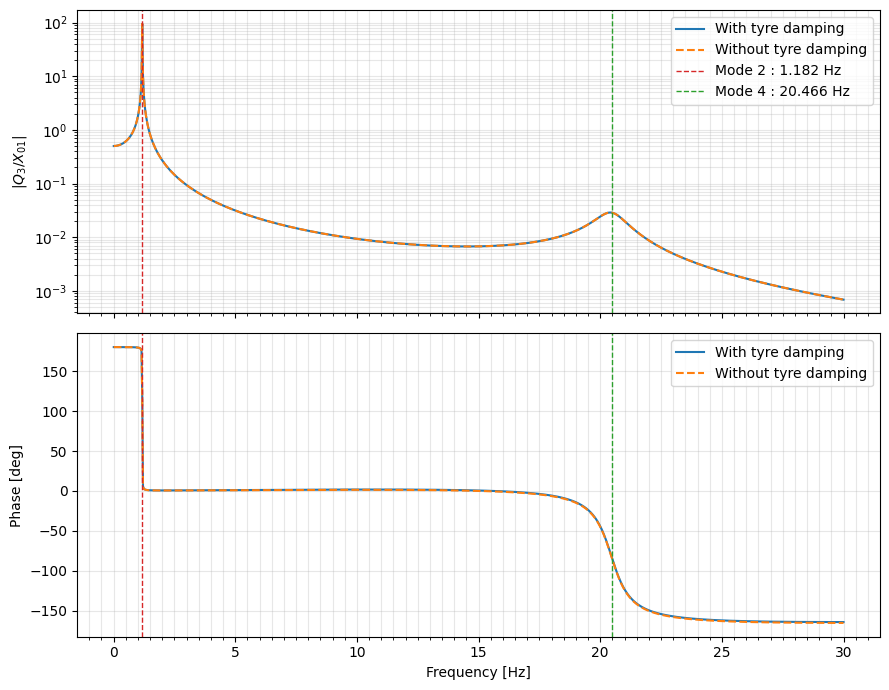

0.028722453816403027
0.028720079329944
magnitude relative error (mode 4) :  0.008267004184960104 %


In [40]:
#we re-use the previous code but we will add the simplify transfer function to compare it with the previous one.

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator


def transfer_function_computation_Q3(freq,m,b,k,M0,B0,K0) :
  w=2*np.pi*freq
  transfer_function=-L*(B0*1j*w+K0)*(b*1j*w+k)/((-IG*w*w)*(-m*w*w+1j*w*(b+B0)+k+K0)+(L**2/2)*(B0*1j*w+K0)*(-m*w*w+1j*w*b+k))
  return transfer_function

#to compute with ONLY the force vector simplification !!! (we do not say b=0 in the system dynamic but only in the force vector !)
def transfer_function_simplify_computation_Q3(freq,m,b,k,M0,B0,K0) :
  w=2*np.pi*freq
  transfer_function_simplify_Q3=-L*(B0*1j*w+K0)*k/((-IG*w*w)*(-m*w*w+1j*w*(b+B0)+k+K0)+(L**2/2)*(B0*1j*w+K0)*(-m*w*w+1j*w*b+k))
  return transfer_function_simplify_Q3

#full model initialisation
freq=np.linspace(0.01,30,1000)
transfer_function_Q3 = np.zeros(np.size(freq),dtype=complex)
transfer_function_Q3_magnitude = np.zeros(np.size(freq))
transfer_function_Q3_phase = np.zeros(np.size(freq))

#simplify model initialisation
transfer_function_simplify_Q3 = np.zeros(np.size(freq),dtype=complex)
transfer_function_simplify_Q3_magnitude = np.zeros(np.size(freq))
transfer_function_simplify_Q3_phase = np.zeros(np.size(freq))

#then we evaluate for each freq and for both model the transfer function value (complex)
for i in range (np.size(freq)) :
  transfer_function_Q3[i]=transfer_function_computation_Q3(freq[i],m,b,k,M0,B0,K0)
  transfer_function_simplify_Q3[i]=transfer_function_simplify_computation_Q3(freq[i],m,b,k,M0,B0,K0)

#then we take the full vector of complex number evaluated in the loop and we compute the modulus and the phase for the full and simplify model
transfer_function_Q3_magnitude=np.abs(transfer_function_Q3)
transfer_function_Q3_phase=np.unwrap(np.angle(transfer_function_Q3)) * 180/np.pi #unwrap cause we could exceed the -pi;pi intervall (which will result in jumps in the plot...) + 180/pi to convert into degrees :)

transfer_function_simplify_Q3_magnitude=np.abs(transfer_function_simplify_Q3)
transfer_function_simplify_Q3_phase=np.unwrap(np.angle(transfer_function_simplify_Q3)) * 180/np.pi



#============== plot section =================== (Use of AI here to generate structurate plot)

f_modes = [1.1821385236486825,20.46614924817183]
labels  = [f"Mode 2 : {f_modes[0]:.3f} Hz", f"Mode 4 : {f_modes[1]:.3f} Hz"]
colors  = ['tab:red', 'tab:green']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

# Magnitude plot
ax1.semilogy(freq, transfer_function_Q3_magnitude,
             color='tab:blue', label='With tyre damping')

ax1.semilogy(freq, transfer_function_simplify_Q3_magnitude,
             color='tab:orange', linestyle='--', label='Without tyre damping')

ax1.set_ylabel(r'$|Q_3/X_{01}|$')
ax1.grid(True, which='both', alpha=0.3)

# Phase plot
ax2.plot(freq, transfer_function_Q3_phase,
         color='tab:blue', label='With tyre damping')

ax2.plot(freq, transfer_function_simplify_Q3_phase,
         color='tab:orange', linestyle='--', label='Without tyre damping')

ax2.set_ylabel('Phase [deg]')
ax2.set_xlabel('Frequency [Hz]')
ax2.grid(True, which='both', alpha=0.3)

# Plot of the eigen frequencies
for f0, lab, c in zip(f_modes, labels, colors):
    ax1.axvline(f0, color=c, ls='--', lw=1, label=lab)
    ax2.axvline(f0, color=c, ls='--', lw=1)
    ax1.xaxis.set_minor_locator(MultipleLocator(0.5))

ax1.legend()
ax2.legend()

plt.tight_layout()
plt.show()

#We are just evaluating the TF at the fourth mode (where the discrepency is visible between the two models) to compute the relative error
f0 = 20.46614924817183
print(abs(transfer_function_computation_Q3(f0, m, b, k, M0, B0, K0)))   # Full model
print(abs(transfer_function_simplify_computation_Q3(f0, m, b, k, M0, B0, K0)))   # No tyre damping (b=0 in the force) model
rel_error=(abs(transfer_function_simplify_computation_Q3(f0, m, b, k, M0, B0, K0))-abs(transfer_function_computation_Q3(f0, m, b, k, M0, B0, K0)))/abs(transfer_function_computation_Q3(f0, m, b, k, M0, B0, K0))*100 #in percent
print('magnitude relative error (mode 4) : ',abs(rel_error),'%')

The simplification applied to the force vector is also entirely reasonable for the 2 antisymetric modes (2 and 4). By comparing the two transmissibility values (simplified and full) at 20.466 Hz, we obtain a relative error of the order of $\epsilon_{rel}\approx0.0083\%$ also !

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

6. The transmissibilities are used in the theory of vibration isolation. Comment on the shape of these and make a link with the theory in the course. In your opinion, which frequency bands correspond to the amplification and the isolation domain? What role do the wheels play in the isolation?

</div>


Comme vu dans le cours, 2 régions distinctent peuvent être observées sur nos transmissibilité. La première est une région d'amplification à basse fréquence $f\in[0;1.45] Hz$. La seconde est notre isolation domain ($|X_3/X_{01}<1)|$ $f\in[1.5;+\infty] Hz$. 2 plots peuvent s'avérer intéressant pour comparer à la théorie : Premièrement, nous pouvons regarder le comportement de $X_3/X_{01}$ en fonction de l'amortissement du pneu $b$ et de l'amortisseur $B_0$ (indépendemment). Deuxièmement, nous pouvons plot $X_3/X_{01}$ et $X_1/X_{01}$ sur un même graphique pour constater le filtrage apporté par la roue.

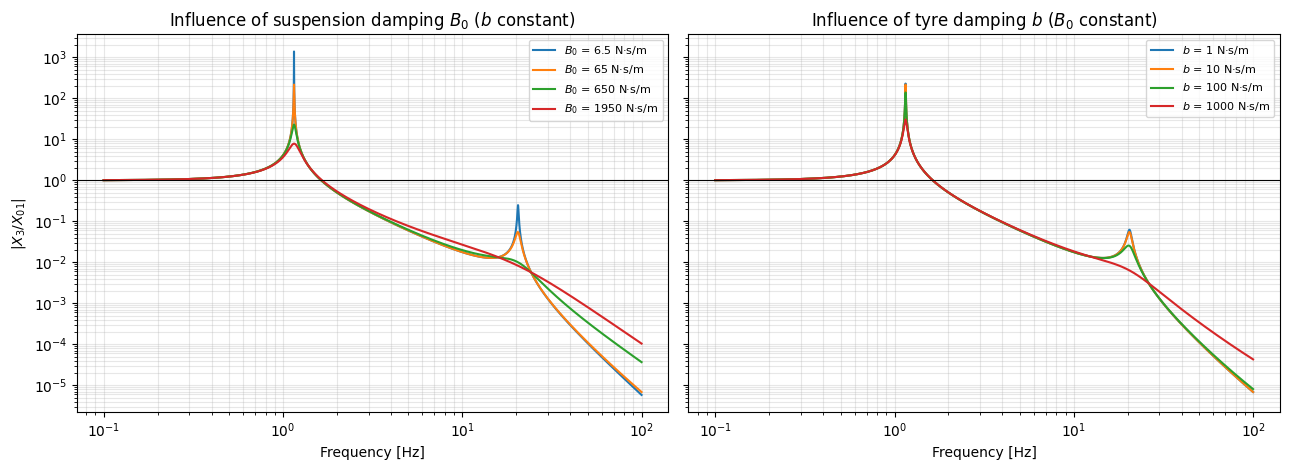

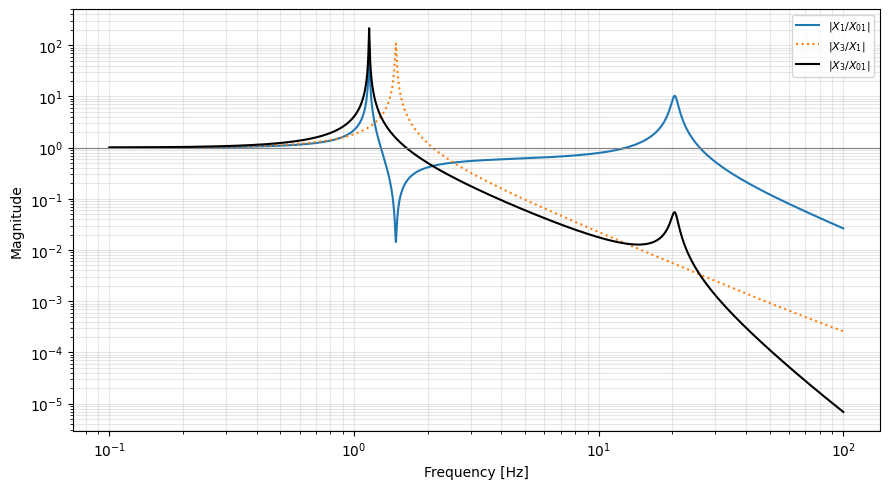

In [45]:

def transfer_function_computation_X1(freq, m, b, k, M0, B0, K0):          # X1/X01
    s = 1j*2*np.pi*freq
    D = M0*s**2 + 2*B0*s + 2*K0
    den = (m*s**2 + b*s + k)*D + (B0*s + K0)*M0*s**2
    return (b*s + k)*D/den

freq = np.logspace(-1, 2, 60000)             # 0.1 à 100 Hz

# ---------- Figure 1 : influence de B0 et de b  ----------
B0_list = [B0/10, B0, 10*B0, 30*B0]          # b cnst (je prends la valeur de base)
b_list  = [b/10, b, 10*b, 100*b]             # B0 cnst (idem)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for Bv in B0_list:
    axA.loglog(freq, np.abs(transfer_function_computation_X3(freq, m, b, k, M0, Bv, K0)), label=f'$B_0$ = {Bv:g} N·s/m')
for bv in b_list:
    axB.loglog(freq, np.abs(transfer_function_computation_X3(freq, m, bv, k, M0, B0, K0)), label=f'$b$ = {bv:g} N·s/m')

axA.set_title(r'Influence of suspension damping $B_0$ ($b$ constant)')
axB.set_title(r'Influence of tyre damping $b$ ($B_0$ constant)')
for ax in (axA, axB):
    ax.axhline(1, color='k', lw=0.8)
    ax.set_xlabel('Frequency [Hz]')
    ax.grid(True, which='both', alpha=0.3)
    ax.legend(fontsize=8)
axA.set_ylabel(r'$|X_3/X_{01}|$')
plt.tight_layout(); plt.show()

# Figure 2 : To see the filter
t3 = transfer_function_computation_X3(freq, m, b, k, M0, B0, K0)
t1 = transfer_function_computation_X1(freq, m, b, k, M0, B0, K0)
t31 = t3/t1

fig, ax = plt.subplots(figsize=(9, 5))
ax.loglog(freq, np.abs(t1),  label=r'$|X_1/X_{01}|$')
ax.loglog(freq, np.abs(t31), ls=':', label=r'$|X_3/X_1|$ ')
ax.loglog(freq, np.abs(t3),  color='k', label=r'$|X_3/X_{01}|$')
ax.axhline(1, color='gray', lw=0.8)
ax.set_xlabel('Frequency [Hz]'); ax.set_ylabel('Magnitude')
ax.grid(True, which='both', alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

On remarque que la roue joue principalement sur les hautes fréquences (modes autour de 20Hz). Ajouter de l'amortissement sur la roue aplatit la résonance des modes 3 et 4 (ici on ne voit que le 3) et dégrade le filtrage pour des fréquences supérieures à $\approx$20Hz (comme vu dans le cours théorique). L'amortisseur, quant à lui, se charge des basses modes à basse fréquence (modes 1 et 2) et de la même façon, augmenter $B_0$ tasse les 2 premières résonances (on ne voit que la première) et dégrade le filtrage au delà de $\approx$ 1,5Hz.

## **2.2 Projection in the modal basis**


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Using the simplified force vector, project the equations of motion in the modal domain. Are the equations uncoupled? Why?

</div>


In [28]:
### Add your code here

In [29]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. If they are coupled, propose a simplification to decouple the equations of motion, and check its validity by comparing the transmissibility curves $X_{3}/X_{01}$ (assume $X_{01} = X_{02}$ as above), and $q_{3}/X_{01}$ (assume $X_{01} = −X_{02}$ as above) obtained with the full model, and with the decoupled modal projection approach. Is your assumption valid?

</div>


In [30]:
### Add your code here

In [31]:
### Add your code here

# **3. Time Domain Computations**

Assume now a given road profile $w$ and $X_{01} \neq X_{02}$. Using the equations with ***absolute coordinates***, and using the simplified force vector used above:


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Knowing that the frequency of excitation depends on the velocity of the car $v$ and the road profile (in particular the amplitude of its different wavelengths) and using a Fourier transform of the road profile, plot the frequency content of the excitation for three different speeds of the car ($v=5 m/s$, $v= 10 m/s$ and $v=30m/s$).

*N.B.: The road profile is defined in the **w.csv** file (first column: spatial coordinate, second column: road profile amplitude)*

</div>


In [32]:
### Add your code here

In [33]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. Compute and represent the absolute displacement $X_{3}(t)$ for the three car speeds. Use a convolution between the force vector and the impulse responses, and work with the uncoupled equations in the modal basis. (hint: consider $X_{01}$ and $X_{02}$ as two independent excitation sources, and sum the responses using the property of linearity of the system). Use a relative time ($t/tmax$) in order to plot the curves on the same graph and compare.

*Hint: Use the function `convolve` from `scipy.signal` to compute the convolution as it is faster that numpy*

*Hint: When convolving the force vector with the impulse response, make sure to multiply the result by the time step to get the correct result*
</div>


In [34]:
### Add your code here

In [35]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

3. Represent the frequency content of the three time domain signals obtained. Compare it to the frequency content of the excitation and comment. What differences do you see for the three different velocities and why ?

</div>

In [36]:
### Add your code here

In [37]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

4. Do you notice a difference in the time domain responses in terms of amplitude? Why? Can you make a link with the transmissibility curves computed previously? Can you make a link with the theory covered in the chapter about vibration isolation? At which speed(s) is the car body best isolated?

</div>


### Add your explanation here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

5. Repeat points (2) to (4) for $q_{3}(t)$ at the three different speeds.

</div>


In [38]:
### Add your code here

In [39]:
### Add your code here